In [1]:
import numpy as np
import idx2numpy

In [8]:
def one_hot_encoding(labels):
    vocab_list = sorted(list(set(labels)))
    length = len(labels)
    output = []
    for i in range(length):
        zeros = [0] * len(vocab_list)
        pos = vocab_list.index(labels[i])
        zeros[pos] = 1
        output.append(zeros)
    
    return np.array(output), vocab_list


def init_parameters(inputs, num_filters, filter_size, num_neurons, output):
    in_channels = inputs.shape[3]
    output_col = output.shape[1]
    weights_conv = np.random.randn(filter_size, filter_size, in_channels, num_filters) * np.sqrt(2.0 / (filter_size * filter_size * in_channels))
    bias_conv = np.zeros((1, 1, 1, num_filters))

    H = inputs.shape[1]
    W = inputs.shape[2]
    H_conv = H - filter_size + 1
    W_conv = W - filter_size + 1
    H_pool = H_conv // 2
    W_pool = W_conv // 2

    flatten_dim = H_pool * W_pool * num_filters

    weights = np.random.randn(flatten_dim, num_neurons) * np.sqrt(2.0 / flatten_dim)
    bias = np.zeros((1, num_neurons))

    output_weights = np.random.randn(num_neurons, output_col) * np.sqrt(2.0 / num_neurons)
    output_bias = np.zeros((1,output_col))

    return weights_conv, bias_conv, weights, bias, output_weights, output_bias


def ReLU(z):
    return np.maximum(0,z)

def softmax(z):
    z = z - np.max(z, axis=1, keepdims=True)
    exp_z = np.exp(z)
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)

def Loss(prediction, labels):
    clipped_pred = np.clip(prediction, 1e-15, 1 - 1e-15)
    log_pred = np.log(clipped_pred)
    loss= -1/labels.shape[0] * (np.sum(labels * log_pred))
    return loss


def conv_foward(inputs, weights_conv, bias_conv):
    batch = inputs.shape[0]
    input_height = inputs.shape[1]
    input_width = inputs.shape[2]

    filter_size = weights_conv.shape[0]
    num_filters = weights_conv.shape[3]

    output_height = input_height - filter_size + 1
    output_width = input_width - filter_size + 1

    output = np.zeros((batch, output_height, output_width, num_filters))

    for i in range(output_height):
        for j in range(output_width):
            patch = inputs[:, i : i + filter_size, j : j + filter_size, :]
            output[:, i, j, :] = np.tensordot(patch, weights_conv, axes=([1, 2, 3], [0, 1, 2])) + bias_conv

    return ReLU(output)

def max_pooling(inputs):
    batch = inputs.shape[0]
    input_height = inputs.shape[1]
    input_width = inputs.shape[2]
    input_chan = inputs.shape[3]

    pool_size = 2
    stride = 2
    
    output_height = input_height// 2
    output_width = input_width// 2

    output = np.zeros((batch, output_height, output_width, input_chan))

    for i in range(output_height):
        for j in range(output_width):
            start_i = i * stride
            start_j = j * stride
            patch = inputs[:, start_i : start_i + pool_size, start_j : start_j + pool_size, :]
            output[:, i, j, :] = np.max(patch, axis=(1, 2))

    return output

def flatten(inputs):
    batch = inputs.shape[0]
    height = inputs.shape[1]
    width = inputs.shape[2]
    channels = inputs.shape[3]

    total_features = height * width * channels

    return inputs.reshape(batch, total_features)

def dense_foward(inputs, weights, bias, output_weights, output_bias):
    z_hidden = inputs @ weights + bias
    a_hidden = ReLU(z_hidden)

    output = a_hidden @ output_weights + output_bias
    return z_hidden, a_hidden, output

def Forward_Pass(inputs, weight_conv, bias_conv, weights, bias, output_weights, output_bias):
    conv_output = conv_foward(inputs, weight_conv, bias_conv)

    pooling_out = max_pooling(conv_output)

    inputs_flatten = flatten(pooling_out)

    z_hidden, a_hidden, output = dense_foward(inputs_flatten, weights,bias, output_weights, output_bias)

    prediction = softmax(output)

    return conv_output, pooling_out, z_hidden, a_hidden, inputs_flatten, prediction


def dense_back(predictions, labels, inputs, z_hidden, a_hidden, weights, output_weights):
    batch = labels.shape[0]

    dZ_out = predictions - labels
    dW_out = (a_hidden.T @ dZ_out) / batch
    dB_out = np.sum(dZ_out, axis=0, keepdims=True) / batch

    dZ_hidden = (dZ_out @ output_weights.T) * (z_hidden > 0)
    dW_hidden = (inputs.T @ dZ_hidden) / batch
    dB_hidden = np.sum(dZ_hidden, axis=0, keepdims=True) / batch

    dX_flat = dZ_hidden @ weights.T

    return dW_out, dB_out, dW_hidden, dB_hidden, dX_flat

def unflatten(inputs, pooling_out):
    batch = pooling_out.shape[0]
    height = pooling_out.shape[1]
    width = pooling_out.shape[2]
    channels = pooling_out.shape[3]

    return inputs.reshape(batch, height, width, channels)

def max_pooling_back(d_pooling_out, conv_output):
    pool_size = 2
    stride = 2

    batch = conv_output.shape[0]
    in_height = conv_output.shape[1]
    in_width = conv_output.shape[2]
    channels = conv_output.shape[3]

    pooled_height = d_pooling_out.shape[1]
    pooled_width = d_pooling_out.shape[2]

    d_conv_out = np.zeros((batch, in_height, in_width, channels))

    for i in range(pooled_height):
            for j in range(pooled_width):
                start_i = i * stride
                start_j = j * stride
                patch = conv_output[:, start_i : start_i + pool_size, start_j : start_j + pool_size, :]
                mask = (patch == np.max(patch, axis=(1, 2), keepdims=True))
                error_window = d_pooling_out[:, i, j, :] 
                d_conv_out[:, start_i : start_i + pool_size, start_j : start_j + pool_size, :] += mask * error_window[:, None, None, :]

    return d_conv_out

def conv_back(d_conv_out, conv_output, inputs, weights_conv):
    dZ_conv = d_conv_out * (conv_output > 0)
    batch = inputs.shape[0]
    dB_conv = np.sum(dZ_conv, axis=(0, 1, 2), keepdims=True) / batch

    in_channels = inputs.shape[3]

    filter_size = weights_conv.shape[0]
    num_filters = weights_conv.shape[3]

    dW_conv = np.zeros((filter_size, filter_size, in_channels, num_filters))

    output_height = dZ_conv.shape[1]
    output_width = dZ_conv.shape[2]

    for i in range(output_height):
        for j in range(output_width):
            patch =  inputs[:, i : i + filter_size, j : j + filter_size, :]
            dW_conv += np.tensordot(patch, dZ_conv[:, i, j, :], axes=([0], [0]))

    return dW_conv / batch, dB_conv

def Back_Prop(predictions, labels, inputs, z_hidden, a_hidden, weights, output_weights, pooling_out, conv_output, weights_conv, inputs_flatten):
    dW_out, dB_out, dW_hidden, dB_hidden, dX_flat = dense_back(predictions, labels, inputs_flatten, z_hidden, a_hidden, weights, output_weights)

    d_pooling_out = unflatten(dX_flat, pooling_out)

    d_conv_out = max_pooling_back(d_pooling_out, conv_output)

    dW_conv, dB_conv = conv_back(d_conv_out, conv_output, inputs, weights_conv)

    return dW_out, dB_out, dW_hidden, dB_hidden, dW_conv, dB_conv

def update_parameters(weights_conv, bias_conv, weights, bias, output_weights, output_bias, dW_out, dB_out, dW_hidden, dB_hidden, dW_conv, dB_conv, lr):
    weights_conv -= lr * dW_conv
    bias_conv -= lr * dB_conv

    weights -= lr * dW_hidden
    bias -= lr * dB_hidden

    output_weights -= lr * dW_out
    output_bias -= lr * dB_out



def Train(X_train, Y_train, num_filters, filter_size, num_neurons, epochs, batch_size, lr):
    weights_conv, bias_conv, weights, bias, output_weights, output_bias = init_parameters(X_train, num_filters, filter_size, num_neurons, Y_train)

    num_samples = X_train.shape[0]
    indices = np.arange(num_samples)

    for epoch in range(epochs):
        np.random.shuffle(indices)
        shuffled_X = X_train[indices]
        shuffled_Y = Y_train[indices]

        num_batches = int(np.ceil(num_samples / batch_size))

        for b in range(num_batches):
            start_idx = b * batch_size
            end_idx = min(start_idx + batch_size, num_samples)

            batch_x = shuffled_X[start_idx:end_idx]
            batch_y = shuffled_Y[start_idx:end_idx]

            conv_output, pooling_out, z_hidden, a_hidden, inputs_flatten, prediction = Forward_Pass(batch_x, weights_conv, bias_conv, weights, bias, output_weights, output_bias)
            dW_out, dB_out, dW_hidden, dB_hidden, dW_conv, dB_conv = Back_Prop(prediction, batch_y, batch_x, z_hidden, a_hidden, weights, output_weights, pooling_out, conv_output, weights_conv, inputs_flatten)
            update_parameters(weights_conv, bias_conv, weights, bias, output_weights, output_bias, dW_out, dB_out, dW_hidden,dB_hidden, dW_conv, dB_conv, lr)

        if epoch % 1 == 0:
            _, _, _, _, _, prediction = Forward_Pass(shuffled_X, weights_conv, bias_conv, weights, bias, output_weights, output_bias)
            loss = Loss(prediction, shuffled_Y)
            acc = np.mean(np.argmax(prediction, axis=1) == np.argmax(shuffled_Y, axis=1)) * 100
            print(f"Epoch {epoch + 1}/{epochs} - Loss: {loss:.4f} - Accuracy: {acc:.2f}%")

    _, _, _, _, _, prediction = Forward_Pass(X_train, weights_conv, bias_conv, weights, bias, output_weights, output_bias)
    final_loss = Loss(prediction, Y_train)
    acc = np.mean(np.argmax(prediction, axis=1) == np.argmax(Y_train, axis=1)) * 100
    print(f"Loss: {final_loss:.4f} - Accuracy: {acc:.2f}%")
    return weights_conv, bias_conv, weights, bias, output_weights, output_bias



In [3]:
X_train = idx2numpy.convert_from_file('Dataset/train-images.idx3-ubyte')
Y_train_raw = idx2numpy.convert_from_file('Dataset/train-labels.idx1-ubyte')

X_test = idx2numpy.convert_from_file('Dataset/t10k-images.idx3-ubyte')
Y_test_raw = idx2numpy.convert_from_file('Dataset/t10k-labels.idx1-ubyte')


X_train = X_train.reshape(-1, 28, 28, 1) / 255.0
X_test = X_test.reshape(-1, 28, 28, 1) / 255.0


Y_train, vocab = one_hot_encoding(Y_train_raw)
Y_test, _ = one_hot_encoding(Y_test_raw)

In [17]:
weights_conv, bias_conv, weights, bias, output_weights, output_bias = Train(
    X_train[:1000], Y_train[:1000],
    num_filters=4,
    filter_size=3,
    num_neurons=32,
    epochs=20,
    batch_size=32,
    lr=0.01
)

Epoch 1/20 - Loss: 1.5722 - Accuracy: 54.20%
Epoch 2/20 - Loss: 1.1789 - Accuracy: 67.40%
Epoch 3/20 - Loss: 0.9104 - Accuracy: 75.10%
Epoch 4/20 - Loss: 0.7465 - Accuracy: 78.60%
Epoch 5/20 - Loss: 0.6467 - Accuracy: 83.20%
Epoch 6/20 - Loss: 0.5740 - Accuracy: 83.80%
Epoch 7/20 - Loss: 0.5313 - Accuracy: 84.90%
Epoch 8/20 - Loss: 0.4698 - Accuracy: 87.70%
Epoch 9/20 - Loss: 0.4455 - Accuracy: 87.90%
Epoch 10/20 - Loss: 0.4238 - Accuracy: 87.80%
Epoch 11/20 - Loss: 0.4104 - Accuracy: 88.90%
Epoch 12/20 - Loss: 0.3646 - Accuracy: 90.10%
Epoch 13/20 - Loss: 0.3528 - Accuracy: 90.00%
Epoch 14/20 - Loss: 0.3664 - Accuracy: 89.70%
Epoch 15/20 - Loss: 0.3196 - Accuracy: 91.00%
Epoch 16/20 - Loss: 0.3187 - Accuracy: 91.50%
Epoch 17/20 - Loss: 0.2985 - Accuracy: 91.70%
Epoch 18/20 - Loss: 0.2701 - Accuracy: 92.80%
Epoch 19/20 - Loss: 0.2572 - Accuracy: 93.80%
Epoch 20/20 - Loss: 0.2532 - Accuracy: 93.40%
Loss: 0.2532 - Accuracy: 93.40%


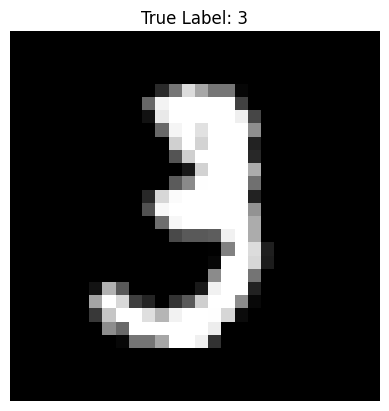

In [19]:
import matplotlib.pyplot as plt
index = 10

# Extract the 28x28 image and corresponding label
image = X_train[index, :, :, 0]
label = np.argmax(Y_train[index])

# Render the image
plt.imshow(image, cmap='gray')
plt.title(f"True Label: {label}")
plt.axis('off')
plt.show()

In [20]:
_, _, _, _, _, test_preds = Forward_Pass(
    X_test, 
    weights_conv, bias_conv, 
    weights, bias, 
    output_weights, output_bias
)

test_acc = np.mean(np.argmax(test_preds, axis=1) == np.argmax(Y_test, axis=1)) * 100
print(f"Test Set Accuracy: {test_acc:.2f}%")

Test Set Accuracy: 84.73%


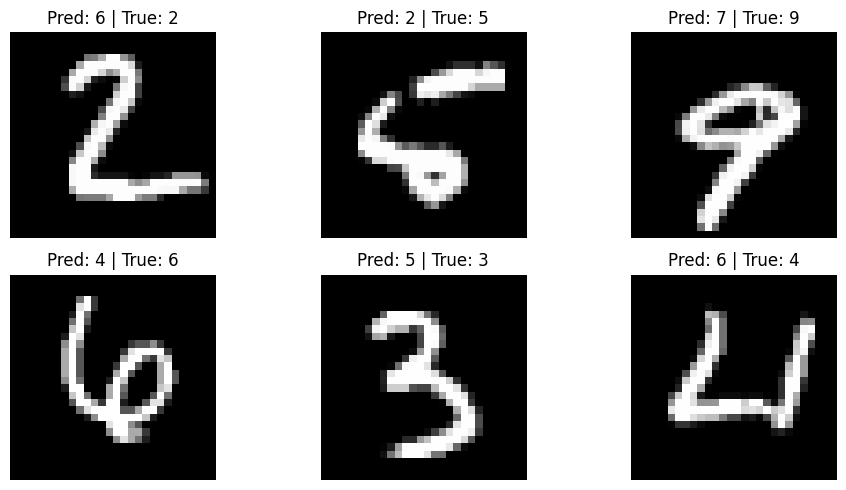

In [21]:
import matplotlib.pyplot as plt

# Find indices where model made wrong predictions
pred_labels = np.argmax(test_preds, axis=1)
true_labels = np.argmax(Y_test, axis=1)
wrong_indices = np.where(pred_labels != true_labels)[0]

# Plot the first 6 misclassified digits
plt.figure(figsize=(10, 5))
for i, idx in enumerate(wrong_indices[:6]):
    plt.subplot(2, 3, i + 1)
    plt.imshow(X_test[idx].reshape(28, 28), cmap='gray')
    plt.title(f"Pred: {pred_labels[idx]} | True: {true_labels[idx]}")
    plt.axis('off')
plt.tight_layout()
plt.show()